# Deep Neural Network Architectures for Movement Disorder Screening

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score, precision_score, recall_score, roc_auc_score

np.random.seed(42)
tf.random.set_seed(42)

Course Model Rules verification: architecture depth, layer counts, and parameter counts

In [2]:
def build_strided_bilstm(input_shape=(300, 6), num_classes=3):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_strided_bigru(input_shape=(300, 6), num_classes=3):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.GRU(32, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.GRU(16))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_combination_model(input_shape=(300, 6), feature_dim=30, num_classes=3):
    sig_inp = layers.Input(shape=input_shape)
    x_sig = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(sig_inp)
    x_sig = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x_sig)
    x_sig = layers.MaxPooling1D(2)(x_sig)
    x_sig = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x_sig)
    x_sig = layers.Dropout(0.3)(x_sig)
    x_sig = layers.Bidirectional(layers.LSTM(16))(x_sig)
    x_sig = layers.Dropout(0.3)(x_sig)
    
    feat_inp = layers.Input(shape=(feature_dim,))
    x_feat = layers.Dense(32, activation="relu")(feat_inp)
    x_feat = layers.Dropout(0.3)(x_feat)
    
    merged = layers.Concatenate()([x_sig, x_feat])
    h = layers.Dense(32, activation="relu")(merged)
    out = layers.Dense(num_classes, activation="softmax")(h)
    model = models.Model(inputs=[sig_inp, feat_inp], outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model_specs = [
    {"Model": "Strided Conv1D + BiLSTM", "Architecture": "Input(300,6) -> Conv1D(32,s2) -> Conv1D(32,s2) -> MaxPool(2) -> BiLSTM(32) -> BiLSTM(16) -> Dense(32) -> Dense(3)", "Layers": 6, "Params": build_strided_bilstm().count_params()},
    {"Model": "Strided Conv1D + BiGRU", "Architecture": "Input(300,6) -> Conv1D(32,s2) -> Conv1D(32,s2) -> MaxPool(2) -> BiGRU(32) -> BiGRU(16) -> Dense(32) -> Dense(3)", "Layers": 6, "Params": build_strided_bigru().count_params()},
    {"Model": "Combination (CNN-BiLSTM + RF Features)", "Architecture": "Signal(300,6) -> Conv1D(32,s2)x2 -> MaxPool(2) -> BiLSTM(32,16) + Features(30) -> Dense(32) -> Concat -> Dense(32) -> Dense(3)", "Layers": 7, "Params": build_combination_model().count_params()}
]
print(pd.DataFrame(model_specs).to_string(index=False))

                                 Model                                                                                                                   Architecture  Layers  Params
               Strided Conv1D + BiLSTM              Input(300,6) -> Conv1D(32,s2) -> Conv1D(32,s2) -> MaxPool(2) -> BiLSTM(32) -> BiLSTM(16) -> Dense(32) -> Dense(3)       6   32259
                Strided Conv1D + BiGRU                Input(300,6) -> Conv1D(32,s2) -> Conv1D(32,s2) -> MaxPool(2) -> BiGRU(32) -> BiGRU(16) -> Dense(32) -> Dense(3)       6   25795
Combination (CNN-BiLSTM + RF Features) Signal(300,6) -> Conv1D(32,s2)x2 -> MaxPool(2) -> BiLSTM(32,16) + Features(30) -> Dense(32) -> Concat -> Dense(32) -> Dense(3)       7   34275


Loading Track 1 primary dataset, handcrafted features, and 3-seed 5-fold splits with amplitude-preserving normalization

In [3]:
pads_data = np.load(os.path.join("..", "results", "pads_primary_100hz.npz"))["windows"]
pads_meta = pd.read_csv(os.path.join("..", "results", "pads_primary_100hz_metadata.csv"))
pads_features = np.load(os.path.join("..", "results", "pads_features_100hz.npy"))
fold_splits = np.load(os.path.join("..", "results", "fold_splits_3seeds.npz"))

y_pads = pads_meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values
groups_pads = pads_meta["subject_id"].values
target_names = ["Normal", "Parkinsons-like", "ET-like"]
unique_subs = pads_meta["subject_id"].unique()
sub_true = np.array([y_pads[groups_pads == s][0] for s in unique_subs])

Xd_pads = pads_data - pads_data.mean(axis=1, keepdims=True)

tr0 = fold_splits["split_42_tr_0"]
sample_ch_std = Xd_pads[tr0].std(axis=(0, 1))
sample_ch_std[sample_ch_std == 0] = 1.0
sample_norm = (Xd_pads[tr0] / sample_ch_std).astype(np.float32)

print("=== Normalization Verification (Amplitude Preserved) ===")
print("Training Channel Mean:", np.mean(sample_norm, axis=(0, 1)))
print("Training Channel Std:", np.std(sample_norm, axis=(0, 1)))
print("ET-like Mean Absolute Amplitude (normalized):", np.mean(np.abs(sample_norm[y_pads[tr0] == 2])))
print("Normal Mean Absolute Amplitude (normalized):", np.mean(np.abs(sample_norm[y_pads[tr0] == 0])))
print("Parkinsons-like Mean Absolute Amplitude (normalized):", np.mean(np.abs(sample_norm[y_pads[tr0] == 1])))

=== Normalization Verification (Amplitude Preserved) ===
Training Channel Mean: [-5.3761054e-12 -1.6604873e-10  7.1994279e-11 -1.2631168e-10
  3.6126793e-11 -2.4775859e-10]


Training Channel Std: [0.9987267  0.9998968  0.99876463 0.9997525  0.99945    1.0000325 ]
ET-like Mean Absolute Amplitude (normalized): 0.57702416
Normal Mean Absolute Amplitude (normalized): 0.10263682
Parkinsons-like Mean Absolute Amplitude (normalized): 0.25634593


Evaluation function across 3 fold seeds (5 folds each) with subject bootstrap CIs and AUROC

In [4]:
def evaluate_architecture_3splits(arch_name, builder_fn, is_combo=False):
    split_seeds = [42, 43, 44]
    seed_sub_f1 = []
    seed_sub_bacc = []
    seed_sub_probs = []
    seed_win_probs = []
    sample_history = None
    
    for s in split_seeds:
        tf.random.set_seed(s)
        np.random.seed(s)
        
        oof_probs = np.zeros((len(y_pads), 3), dtype=np.float32)
        
        for fold in range(5):
            tr_idx = fold_splits[f"split_{s}_tr_{fold}"]
            te_idx = fold_splits[f"split_{s}_te_{fold}"]
            
            ch_std = Xd_pads[tr_idx].std(axis=(0, 1))
            ch_std[ch_std == 0] = 1.0
            Xn_tr = (Xd_pads[tr_idx] / ch_std).astype(np.float32)
            Xn_te = (Xd_pads[te_idx] / ch_std).astype(np.float32)
            
            val_sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=s)
            sub_tr, sub_va = next(val_sgkf.split(Xn_tr, y_pads[tr_idx], groups_pads[tr_idx]))
            
            cw = compute_class_weight("balanced", classes=np.unique(y_pads[tr_idx][sub_tr]), y=y_pads[tr_idx][sub_tr])
            cw_dict = dict(enumerate(cw))
            
            tf.keras.backend.clear_session()
            model = builder_fn()
            
            callbacks = [
                tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
            ]
            
            if is_combo:
                scaler = StandardScaler()
                feats_tr = scaler.fit_transform(pads_features[tr_idx])
                feats_te = scaler.transform(pads_features[te_idx])
                
                train_x = [Xn_tr[sub_tr], feats_tr[sub_tr]]
                val_x = [Xn_tr[sub_va], feats_tr[sub_va]]
                test_x = [Xn_te, feats_te]
            else:
                train_x = Xn_tr[sub_tr]
                val_x = Xn_tr[sub_va]
                test_x = Xn_te
                
            h = model.fit(
                train_x, y_pads[tr_idx][sub_tr],
                validation_data=(val_x, y_pads[tr_idx][sub_va]),
                epochs=15, batch_size=256, class_weight=cw_dict,
                callbacks=callbacks, verbose=0
            )
            if sample_history is None:
                sample_history = h.history
                
            oof_probs[te_idx] = model.predict(test_x, batch_size=1024, verbose=0)
            
        sub_p = np.array([np.mean(oof_probs[groups_pads == sub], axis=0) for sub in unique_subs])
        sub_pred = np.argmax(sub_p, axis=1)
        s_f1 = f1_score(sub_true, sub_pred, average="macro")
        s_bacc = balanced_accuracy_score(sub_true, sub_pred)
        seed_sub_f1.append(s_f1)
        seed_sub_bacc.append(s_bacc)
        seed_sub_probs.append(sub_p)
        seed_win_probs.append(oof_probs)
        print(f"Split seed {s}: Subject Macro-F1 = {s_f1:.4f}, Subject Balanced Acc = {s_bacc:.4f}")
        
    avg_sub_probs = np.mean(seed_sub_probs, axis=0)
    final_sub_preds = np.argmax(avg_sub_probs, axis=1)
    avg_win_probs = np.mean(seed_win_probs, axis=0)
    final_win_preds = np.argmax(avg_win_probs, axis=1)
    
    mean_sub_f1 = float(f1_score(sub_true, final_sub_preds, average="macro"))
    mean_sub_bacc = float(balanced_accuracy_score(sub_true, final_sub_preds))
    mean_win_f1 = float(f1_score(y_pads, final_win_preds, average="macro"))
    mean_win_bacc = float(balanced_accuracy_score(y_pads, final_win_preds))
    
    auc_normal = float(roc_auc_score(sub_true == 0, avg_sub_probs[:, 0]))
    auc_pd = float(roc_auc_score(sub_true == 1, avg_sub_probs[:, 1]))
    auc_et = float(roc_auc_score(sub_true == 2, avg_sub_probs[:, 2]))
    auc_macro = float((auc_normal + auc_pd + auc_et) / 3.0)
    
    def compute_bootstrap_ci(y_t, probs, metric_fn, n_boot=1000, seed=42):
        rng = np.random.default_rng(seed)
        scores = []
        n = len(y_t)
        for _ in range(n_boot):
            idx = rng.choice(n, size=n, replace=True)
            scores.append(metric_fn(y_t[idx], probs[idx]))
        return float(np.percentile(scores, 2.5)), float(np.percentile(scores, 97.5))
        
    f1_ci = compute_bootstrap_ci(sub_true, avg_sub_probs, lambda yt, p: f1_score(yt, np.argmax(p, axis=1), average="macro"))
    bacc_ci = compute_bootstrap_ci(sub_true, avg_sub_probs, lambda yt, p: balanced_accuracy_score(yt, np.argmax(p, axis=1)))
    
    print(f"\n=== {arch_name} Seed-Averaged Results across 3 Split Seeds ===")
    print(f"Subject Macro-F1 across 3 split seeds: {np.mean(seed_sub_f1):.4f} +- {np.std(seed_sub_f1):.4f}")
    print(f"Pooled Subject-Level Macro-F1: {mean_sub_f1:.4f} [95% Bootstrap CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f}]")
    print(f"Pooled Subject-Level Balanced Acc: {mean_sub_bacc:.4f} [95% Bootstrap CI: {bacc_ci[0]:.4f} - {bacc_ci[1]:.4f}]")
    print(f"Subject One-vs-Rest AUROC: Normal={auc_normal:.4f}, PD={auc_pd:.4f}, ET={auc_et:.4f}, Macro={auc_macro:.4f}")
    print(f"Window-Level Macro-F1: {mean_win_f1:.4f} | Balanced Acc: {mean_win_bacc:.4f}")
    
    cm = confusion_matrix(sub_true, final_sub_preds)
    print("\nSubject-Level Confusion Matrix:")
    print(pd.DataFrame(cm, index=[f"True_{c}" for c in target_names], columns=[f"Pred_{c}" for c in target_names]))
    rec_per_class = cm.diagonal() / cm.sum(axis=1)
    for c, r in zip(target_names, rec_per_class):
        print(f"Recall for {c}: {r:.4f}")
        
    return {
        "Model": arch_name,
        "Sampling_Rate": "100 Hz",
        "Channels": 6,
        "Subject_Macro_F1": mean_sub_f1,
        "Subject_F1_CI_Low": f1_ci[0],
        "Subject_F1_CI_High": f1_ci[1],
        "Subject_Balanced_Acc": mean_sub_bacc,
        "Subject_BAcc_CI_Low": bacc_ci[0],
        "Subject_BAcc_CI_High": bacc_ci[1],
        "AUROC_Normal": auc_normal,
        "AUROC_PD": auc_pd,
        "AUROC_ET": auc_et,
        "AUROC_Macro": auc_macro,
        "Window_Macro_F1": mean_win_f1,
        "Window_Balanced_Acc": mean_win_bacc,
        "History": sample_history
    }

Training and evaluating Model A: Strided Conv1D + BiLSTM across 3 fold seeds (5 folds each)

In [5]:
res_bilstm = evaluate_architecture_3splits(
    "Strided Conv1D + BiLSTM",
    lambda: build_strided_bilstm(),
    is_combo=False
)

Split seed 42: Subject Macro-F1 = 0.5311, Subject Balanced Acc = 0.6342


Split seed 43: Subject Macro-F1 = 0.4941, Subject Balanced Acc = 0.5821


Split seed 44: Subject Macro-F1 = 0.4471, Subject Balanced Acc = 0.5415



=== Strided Conv1D + BiLSTM Seed-Averaged Results across 3 Split Seeds ===
Subject Macro-F1 across 3 split seeds: 0.4907 +- 0.0344
Pooled Subject-Level Macro-F1: 0.4979 [95% Bootstrap CI: 0.4269 - 0.5637]
Pooled Subject-Level Balanced Acc: 0.5954 [95% Bootstrap CI: 0.5213 - 0.6674]
Subject One-vs-Rest AUROC: Normal=0.8023, PD=0.6988, ET=0.8552, Macro=0.7854
Window-Level Macro-F1: 0.4115 | Balanced Acc: 0.5298

Subject-Level Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    71                     8             0
True_Parkinsons-like          122                   123            23
True_ET-like                    5                    11            12
Recall for Normal: 0.8987
Recall for Parkinsons-like: 0.4590
Recall for ET-like: 0.4286


Training and evaluating Model B: Strided Conv1D + BiGRU across 3 fold seeds (5 folds each)

In [6]:
res_bigru = evaluate_architecture_3splits(
    "Strided Conv1D + BiGRU",
    lambda: build_strided_bigru(),
    is_combo=False
)

Split seed 42: Subject Macro-F1 = 0.4491, Subject Balanced Acc = 0.6072


Split seed 43: Subject Macro-F1 = 0.4584, Subject Balanced Acc = 0.5626


Split seed 44: Subject Macro-F1 = 0.4854, Subject Balanced Acc = 0.5689



=== Strided Conv1D + BiGRU Seed-Averaged Results across 3 Split Seeds ===
Subject Macro-F1 across 3 split seeds: 0.4643 +- 0.0154
Pooled Subject-Level Macro-F1: 0.4766 [95% Bootstrap CI: 0.4069 - 0.5387]
Pooled Subject-Level Balanced Acc: 0.5783 [95% Bootstrap CI: 0.5095 - 0.6474]
Subject One-vs-Rest AUROC: Normal=0.7810, PD=0.6694, ET=0.8586, Macro=0.7697
Window-Level Macro-F1: 0.3847 | Balanced Acc: 0.5129

Subject-Level Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    73                     6             0
True_Parkinsons-like          135                   112            21
True_ET-like                    4                    13            11
Recall for Normal: 0.9241
Recall for Parkinsons-like: 0.4179
Recall for ET-like: 0.3929


Training and evaluating Model C: Combination Model (Strided Conv1D-BiLSTM + Standardized RF Feature Branch)

In [7]:
res_combo = evaluate_architecture_3splits(
    "Combination (CNN-BiLSTM + RF Features)",
    lambda: build_combination_model(),
    is_combo=True
)

all_track1_deep = [res_bilstm, res_bigru, res_combo]
track1_deep_clean = []
for r in all_track1_deep:
    item = {k: v for k, v in r.items() if k != "History"}
    track1_deep_clean.append(item)

track1_deep_df = pd.DataFrame(track1_deep_clean)
track1_deep_df.to_csv(os.path.join("..", "results", "metrics", "track1_deep_models.csv"), index=False)
print("=== Track 1 Deep Models Final Summary ===")
print(track1_deep_df.to_string(index=False))

Split seed 42: Subject Macro-F1 = 0.5343, Subject Balanced Acc = 0.6500


Split seed 43: Subject Macro-F1 = 0.4867, Subject Balanced Acc = 0.5976


Split seed 44: Subject Macro-F1 = 0.4786, Subject Balanced Acc = 0.5729



=== Combination (CNN-BiLSTM + RF Features) Seed-Averaged Results across 3 Split Seeds ===
Subject Macro-F1 across 3 split seeds: 0.4999 +- 0.0246
Pooled Subject-Level Macro-F1: 0.5216 [95% Bootstrap CI: 0.4573 - 0.5833]
Pooled Subject-Level Balanced Acc: 0.6279 [95% Bootstrap CI: 0.5487 - 0.6981]
Subject One-vs-Rest AUROC: Normal=0.8212, PD=0.7203, ET=0.8591, Macro=0.8002
Window-Level Macro-F1: 0.4339 | Balanced Acc: 0.5438

Subject-Level Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    67                    11             1
True_Parkinsons-like          103                   134            31
True_ET-like                    4                     9            15
Recall for Normal: 0.8481
Recall for Parkinsons-like: 0.5000
Recall for ET-like: 0.5357
=== Track 1 Deep Models Final Summary ===
                                 Model Sampling_Rate  Channels  Subject_Macro_F1  Subject_F1_CI_Low  Subject_F1_CI_High  Subject

Plotting representative training and validation curves

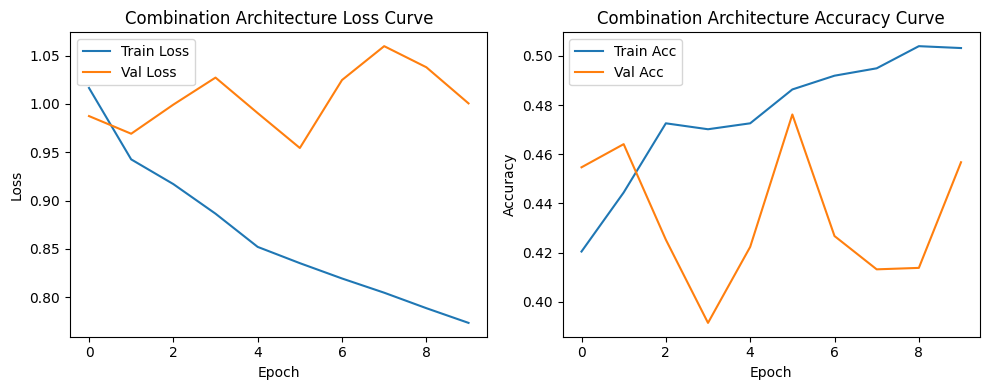

In [8]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(res_combo["History"]["loss"], label="Train Loss")
plt.plot(res_combo["History"]["val_loss"], label="Val Loss")
plt.title("Combination Architecture Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(res_combo["History"]["accuracy"], label="Train Acc")
plt.plot(res_combo["History"]["val_accuracy"], label="Val Acc")
plt.title("Combination Architecture Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.savefig(os.path.join("..", "results", "plots", "combination_model_training_curves.png"), dpi=150)
plt.show()

Track 1 Comparison: Evaluating 16 Hz Accel-Only Architecture

In [9]:
pads_16hz_data = np.load(os.path.join("..", "results", "pads_within_source_16hz.npz"))["windows"]
Xd_16 = pads_16hz_data - pads_16hz_data.mean(axis=1, keepdims=True)

tr_16 = fold_splits["split_42_tr_0"]
te_16 = fold_splits["split_42_te_0"]

ch_std_16 = Xd_16[tr_16].std(axis=(0, 1))
ch_std_16[ch_std_16 == 0] = 1.0
Xn_tr_16 = (Xd_16[tr_16] / ch_std_16).astype(np.float32)
Xn_te_16 = (Xd_16[te_16] / ch_std_16).astype(np.float32)

cw_16 = compute_class_weight("balanced", classes=np.unique(y_pads[tr_16]), y=y_pads[tr_16])

def build_16hz_bilstm(input_shape=(48, 3), num_classes=3):
    inp = layers.Input(shape=input_shape)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(inp)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

m16 = build_16hz_bilstm()
m16.fit(Xn_tr_16, y_pads[tr_16], batch_size=256, epochs=15, class_weight=dict(enumerate(cw_16)), verbose=0)
oof_16 = m16.predict(Xn_te_16, batch_size=1024, verbose=0)
win_preds_16 = np.argmax(oof_16, axis=1)

print("=== Track 1 16 Hz Accel-Only Comparison ===")
print(f"Window Macro-F1: {f1_score(y_pads[te_16], win_preds_16, average='macro'):.4f}")
print(f"Window Balanced Acc: {balanced_accuracy_score(y_pads[te_16], win_preds_16):.4f}")

=== Track 1 16 Hz Accel-Only Comparison ===
Window Macro-F1: 0.3055
Window Balanced Acc: 0.4857


Track 2 Evaluation: UEA Epilepsy Test Set across 3 random seeds

In [10]:
uea_data = np.load(os.path.join("..", "results", "uea_within_source_16hz.npz"))["windows"]
uea_meta = pd.read_csv(os.path.join("..", "results", "uea_within_source_metadata.csv"))
y_uea = (uea_meta["cohort_label"] == "Seizure-like (simulated)").astype(int).values

train_mask = (uea_meta["split"] == "train").values
test_mask = (uea_meta["split"] == "test").values

Xd_uea = uea_data - uea_data.mean(axis=1, keepdims=True)
ch_std_uea = Xd_uea[train_mask].std(axis=(0, 1))
ch_std_uea[ch_std_uea == 0] = 1.0
Xn_uea = (Xd_uea / ch_std_uea).astype(np.float32)

train_series_ids = uea_meta.loc[train_mask, "series_id"].unique()
test_series_ids = uea_meta.loc[test_mask, "series_id"].unique()
test_series_true = np.array([y_uea[uea_meta["series_id"] == sid][0] for sid in test_series_ids])
total_test_seizures = int(np.sum(test_series_true == 1))

uea_seeds = [42, 43, 44]
uea_seed_probs = []
uea_detected_counts = []

def build_uea_strided_bilstm(input_shape=(48, 3), num_classes=2):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(inp)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for seed in uea_seeds:
    np.random.seed(seed)
    tf.random.set_seed(seed)
    val_series_ids = np.random.choice(train_series_ids, size=int(len(train_series_ids) * 0.2), replace=False)
    sub_tr_mask = train_mask & (~uea_meta["series_id"].isin(val_series_ids).values)
    sub_val_mask = train_mask & (uea_meta["series_id"].isin(val_series_ids).values)
    
    cw_uea = compute_class_weight("balanced", classes=np.unique(y_uea[sub_tr_mask]), y=y_uea[sub_tr_mask])
    cw_uea_dict = dict(enumerate(cw_uea))
    
    tf.keras.backend.clear_session()
    m_uea = build_uea_strided_bilstm()
    cb_uea = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)
    ]
    m_uea.fit(
        Xn_uea[sub_tr_mask], y_uea[sub_tr_mask],
        validation_data=(Xn_uea[sub_val_mask], y_uea[sub_val_mask]),
        epochs=40, batch_size=32, class_weight=cw_uea_dict,
        callbacks=cb_uea, verbose=0
    )
    
    test_probs = m_uea.predict(Xn_uea[test_mask], verbose=0)[:, 1]
    series_probs = np.array([np.mean(test_probs[uea_meta.loc[test_mask, "series_id"] == sid]) for sid in test_series_ids])
    uea_seed_probs.append(series_probs)
    det = int(np.sum((test_series_true == 1) & (series_probs >= 0.5)))
    uea_detected_counts.append(det)
    print(f"Seed {seed}: Detected {det} of {total_test_seizures} test seizures")

avg_test_probs = np.mean(uea_seed_probs, axis=0)
final_series_preds = (avg_test_probs >= 0.5).astype(int)
detected_uea = int(np.sum((test_series_true == 1) & (final_series_preds == 1)))
f1_uea = float(f1_score(test_series_true, final_series_preds, average="macro"))
rec_uea = float(recall_score(test_series_true, final_series_preds, pos_label=1))
prec_uea = float(precision_score(test_series_true, final_series_preds, pos_label=1))

print("\n=== Track 2 Deep Model Results on Held-Out Test Set (Seed-Averaged) ===")
print(f"Deep Conv1D+BiLSTM: Detected {detected_uea} of {total_test_seizures} test seizures (range across seeds: {min(uea_detected_counts)}-{max(uea_detected_counts)})")
print(f"Seizure Recall: {rec_uea:.4f} | Precision: {prec_uea:.4f} | Macro-F1: {f1_uea:.4f}")

track2_deep_records = [
    {"Model": "Strided Conv1D + BiLSTM", "Series_Detected": f"{detected_uea} of {total_test_seizures}", "Seizure_Recall": rec_uea, "Seizure_Precision": prec_uea, "Macro_F1": f1_uea}
]
pd.DataFrame(track2_deep_records).to_csv(os.path.join("..", "results", "metrics", "track2_deep_models.csv"), index=False)

Seed 42: Detected 25 of 34 test seizures


Seed 43: Detected 26 of 34 test seizures


Seed 44: Detected 24 of 34 test seizures

=== Track 2 Deep Model Results on Held-Out Test Set (Seed-Averaged) ===
Deep Conv1D+BiLSTM: Detected 25 of 34 test seizures (range across seeds: 24-26)
Seizure Recall: 0.7353 | Precision: 1.0000 | Macro-F1: 0.9030


Track 3 Demonstration: Mixed 4-Class Model (Demonstration Only - Explicit Confounding Disclaimer)

In [11]:
demo_data = np.load(os.path.join("..", "results", "demonstration_unified_16hz.npz"))["windows"]
demo_meta = pd.read_csv(os.path.join("..", "results", "demonstration_unified_metadata.csv"))

Xd_demo = demo_data - demo_data.mean(axis=1, keepdims=True)
ch_std_demo = Xd_demo.std(axis=(0, 1))
ch_std_demo[ch_std_demo == 0] = 1.0
Xn_demo = (Xd_demo / ch_std_demo).astype(np.float32)

label_map_4class = {"Normal": 0, "Parkinsons-like": 1, "ET-like": 2, "Seizure-like (simulated)": 3}
y_demo = demo_meta["cohort_label"].map(label_map_4class).values
groups_demo = demo_meta["subject_id"].values

cw_demo = compute_class_weight("balanced", classes=np.unique(y_demo), y=y_demo)

demo_sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
demo_tr, demo_te = next(demo_sgkf.split(Xn_demo, y_demo, groups_demo))

def build_demo_model(input_shape=(48, 3), num_classes=4):
    inp = layers.Input(shape=input_shape)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(inp)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

tf.keras.backend.clear_session()
m_demo = build_demo_model()
m_demo.fit(Xn_demo[demo_tr], y_demo[demo_tr], batch_size=256, epochs=10, class_weight=dict(enumerate(cw_demo)), verbose=0)
preds_demo = np.argmax(m_demo.predict(Xn_demo[demo_te], verbose=0), axis=1)

f1_demo = float(f1_score(y_demo[demo_te], preds_demo, average="macro"))
print(f"Mixed 4-Class Demonstration Macro-F1: {f1_demo:.4f}")
print("Warning: This mixed 4-class model is for demonstration purposes only. Cross-source separation is confounded by hardware and activity differences.")

Mixed 4-Class Demonstration Macro-F1: 0.2606


Consolidated Summary Tables for Deep Architectures

In [12]:
print("=== Consolidated Track 1 Deep Model Results ===")
print(track1_deep_df.to_string(index=False))

print("\n=== Consolidated Track 2 Deep Model Results ===")
print(pd.DataFrame(track2_deep_records).to_string(index=False))

=== Consolidated Track 1 Deep Model Results ===
                                 Model Sampling_Rate  Channels  Subject_Macro_F1  Subject_F1_CI_Low  Subject_F1_CI_High  Subject_Balanced_Acc  Subject_BAcc_CI_Low  Subject_BAcc_CI_High  AUROC_Normal  AUROC_PD  AUROC_ET  AUROC_Macro  Window_Macro_F1  Window_Balanced_Acc
               Strided Conv1D + BiLSTM        100 Hz         6          0.497863           0.426855            0.563723              0.595420             0.521336              0.667417      0.802258  0.698842  0.855187     0.785429         0.411533             0.529822
                Strided Conv1D + BiGRU        100 Hz         6          0.476596           0.406873            0.538661              0.578273             0.509498              0.647448      0.780961  0.669445  0.858584     0.769663         0.384658             0.512904
Combination (CNN-BiLSTM + RF Features)        100 Hz         6          0.521572           0.457334            0.583253              0.627939 